# XGBoost Model

CRISP-DM phase: Modelling + Evaluation

This notebook trains XGBoost to predict whether a Kenyan county will have a recorded flood next month (`flood_next_month`), using the 24 features prepared in the preprocessing notebook plus `flood_this_month` (whether the county flooded this month). XGBoost builds its trees one after the other, and each new tree tries to fix the mistakes of the trees before it.

## 1. Setup and Data Loading

### 1.1 Importing Libraries

In [1]:
import os
import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.model_selection import GroupKFold, RandomizedSearchCV, cross_val_predict, cross_validate
from sklearn.metrics import classification_report, confusion_matrix, recall_score, precision_score, f1_score, roc_auc_score, average_precision_score, precision_recall_curve

### 1.2 Loading the Training and Test Sets

In [2]:
#loading the saved training and test sets (pcode as text)
train = pd.read_csv('../data/train.csv', dtype={'pcode': str})
test = pd.read_csv('../data/test.csv', dtype={'pcode': str})

### 1.3 Features and Target

We predict at the end of month t whether a county floods in month t+1. `flood_this_month` says whether it flooded in month t, which is already known at that moment, so it is a lag of the target, like `rain_lag1`, and it is used as a feature (notebook 01, Section 4.3, checks that it is a clean lag). It also stays in `train` and `test` because it is the persistence baseline in Section 8. Two limits: it assumes this month's floods are known by the end of the month, and many floods last several months, so the model may partly "predict" floods that are already happening. Section 7 therefore scores new floods and continuing floods separately.

In [3]:
#columns that are not features: keys and target (flood_this_month stays a feature and is also the persistence baseline)
not_features = ['pcode', 'county', 'year', 'month', 'flood_next_month']

In [4]:
#separating the features (X) from the target (y)
X_train = train.drop(not_features, axis=1)
y_train = train['flood_next_month']
X_test = test.drop(not_features, axis=1)
y_test = test['flood_next_month']

In [5]:
#shapes and number of floods in each set
print(X_train.shape, y_train.sum())
print(X_test.shape, y_test.sum())

(9870, 25) 882
(2820, 25) 144


In [6]:
#the list of features
print(X_train.columns.tolist())

['flood_this_month', 'rain_mm', 'rain_lag1', 'rain_lag2', 'rain_pct_normal', 'neighbour_rain', 'ndvi_pct_normal', 'oni', 'dmi', 'month_sin', 'month_cos', 'soil_moisture_l1', 'runoff_rank', 'discharge_rank', 'pct_flat', 'area_km2', 'lc_tree', 'lc_grass', 'lc_crop', 'lc_bare', 'pct_within_1km_river', 'pct_water', 'pct_occasional_water', 'pop_density', 'county_flood_rate']


In [7]:
#share of flood rows in each set
print(round(y_train.mean(), 3), round(y_test.mean(), 3))

0.089 0.051


#### Observation

The training set has 9,870 rows with 882 floods (share 0.089) and the test set has 2,820 rows with 144 floods (share 0.051). Both have 25 features: the 24 features of the preprocessing notebook plus `flood_this_month`, which is the first column. The 4 keys and the target are not features. `flood_this_month` is still a column of `train` and `test`, so the persistence baseline can use it. The share of floods is also the PR-AUC of a model with no skill: 0.089 in training and 0.051 in the test set.

## 2. Cross-Validation and How the Settings Are Chosen

All the choices in this notebook (the settings of the model and the probability threshold) are made with 5-fold cross-validation on the training set only. The test set is used once, at the end, and nothing is changed after it.

The folds keep **whole years together** (`GroupKFold` with the year as the group). The counties in the same month share the same weather: `oni` and `dmi` have the same value for every county, and floods often hit many counties at once. If one county's October 2015 is in the training part and another county's October 2015 is in the validation part, the model can learn "October 2015 was a flood month" and the scores look better than they really are. With whole years held out, each fold is tested on years the model has not seen at all. The same folds are used in all the model notebooks.

In [8]:
#5-fold cross-validation that keeps whole years together
year_cv = GroupKFold(n_splits=5)

In [9]:
#years, rows and floods in the validation part of each fold
for fold, (train_idx, val_idx) in enumerate(year_cv.split(X_train, y_train, groups=train['year']), start=1):
    val_rows = train.iloc[val_idx]
    print('fold', fold, 'years', val_rows['year'].unique(), 'rows', len(val_rows), 'floods', val_rows['flood_next_month'].sum(), 'flood rate', round(val_rows['flood_next_month'].mean(), 3))

fold 1 years [2004 2009 2014 2019] rows 2256 floods 128 flood rate 0.057
fold 2 years [2003 2008 2013 2018] rows 2256 floods 175 flood rate 0.078
fold 3 years [2002 2007 2012 2017] rows 1974 floods 211 flood rate 0.107
fold 4 years [2006 2011 2016] rows 1692 floods 174 flood rate 0.103
fold 5 years [2005 2010 2015] rows 1692 floods 194 flood rate 0.115


#### Observation

Each fold holds out whole years: three or four years spread across the period (for example 2004, 2009, 2014 and 2019), so every fold has early, middle and late years. Folds 1 and 2 have 2,256 rows (four full years), folds 4 and 5 have 1,692 rows (three full years), and fold 3 has 1,974 rows because it holds 2002, which only has six months. Together the folds cover all 9,870 rows and all 882 floods once. The flood rate changes from 0.057 in fold 1 (128 floods) to 0.115 in fold 5 (194 floods). Because the folds are not balanced on floods, the scores are expected to change from fold to fold.

### 2.1 How the Settings Are Chosen

The work is done in two jobs.

**Job 1: choose the settings by PR-AUC.** PR-AUC (average precision) looks at all the possible probability cuts at once. It is high when the months that flood get higher probabilities than the months that do not, so it measures how well the model ranks the months. It does not go up just because a model warns more often. A model with no skill scores the share of floods (0.089 in the training set, see Section 1.3). `RandomizedSearchCV` tries 80 combinations of the settings, scores each one with PR-AUC in the 5 year folds and keeps the combination with the highest mean. All the settings are searched together, so a setting is judged together with the others and not alone, and the class weight is one of the settings searched. The values to try are given as plain lists, and `random_state=42` makes the search repeatable.

**Job 2: choose the threshold for 80% recall.** The model gives each month a flood probability, and the threshold decides from which probability on we raise a warning. Recall is still the main goal, because a missed flood is the most dangerous mistake: a county is not warned and lives can be lost. But recall is set by the threshold, not by weakening the model. We take the out-of-fold probabilities (each training row is predicted by a model that did not see its year) and pick the highest threshold where the out-of-fold recall is at least 0.80. The threshold comes from cross-validation only, never from the test set. Precision and the share of months flagged are shown next to recall, because false alarms waste money and staff time and make people stop trusting the warnings. We also checked the threshold with the highest F1 (Section 6.5). 80% recall was chosen because a missed flood is the most dangerous mistake.

**Limits that stay:** `GroupKFold` trains on years both before and after the held-out years, so it is not a pure forecast of the future, and `county_flood_rate` is calculated from all the training years, so the cross-validation scores are slightly optimistic.

## 3. Base Model

XGBoost is first trained with all default settings. It is judged with the PR-AUC and the ROC-AUC of the year folds from Section 2. This is the starting point that the search in Section 4 has to beat. With the default settings XGBoost uses its built-in values for every setting and puts no extra weight on the floods.

In [10]:
#base model with all default settings
model_default = XGBClassifier(random_state=42)

In [11]:
#pr-auc and roc-auc in each fold for the default model
scores_default = cross_validate(model_default, X_train, y_train, cv=year_cv, groups=train['year'], scoring=['average_precision', 'roc_auc'])
print(scores_default['test_average_precision'].round(3))
print(scores_default['test_average_precision'].mean().round(3), scores_default['test_average_precision'].std().round(3))
print(scores_default['test_roc_auc'].mean().round(3), scores_default['test_roc_auc'].std().round(3))

[0.391 0.367 0.288 0.448 0.435]
0.386 0.057
0.78 0.04


#### Observation

The default XGBoost has a mean PR-AUC of 0.386 (std 0.057) and a mean ROC-AUC of 0.78 (std 0.04) in the year folds. It is above the 0.089 of a model with no skill. This is the score the search has to beat.

## 4. Choosing the Settings with a Randomized Search

XGBoost does not have `class_weight`. It has `scale_pos_weight`, which makes each flood row count that many times more than a no-flood row. The balanced value is the number of no-flood rows divided by the number of flood rows.

In [12]:
#balanced value of scale_pos_weight: no-flood rows divided by flood rows
weight = (y_train == 0).sum() / (y_train == 1).sum()
print(round(weight, 2))

10.19


The settings searched are:

- `max_depth`: how many questions in a row each tree can ask.
- `n_estimators`: the number of trees.
- `learning_rate`: the size of the step each new tree is allowed to take. A small value learns slowly and carefully and needs more trees.
- `subsample`: the share of the training rows each tree is allowed to see.
- `colsample_bytree`: the share of the features each tree is allowed to use.
- `min_child_weight`: the smallest total weight of rows a leaf must hold.
- `reg_lambda`: a penalty that shrinks the answer of each leaf.
- `scale_pos_weight`: 1 (no extra weight), 3, or the balanced value.

All of them are searched together, because they work together: for example, a small learning rate needs more trees. The search tries 80 combinations from the lists.

In [13]:
#the values to try for each setting
param_lists = {'max_depth': [1, 2, 3, 4, 5, 6],
               'n_estimators': [25, 50, 100, 200, 400, 800],
               'learning_rate': [0.01, 0.03, 0.04, 0.05, 0.1, 0.3],
               'subsample': [0.3, 0.4, 0.5, 0.56, 0.7, 0.8, 1.0],
               'colsample_bytree': [0.3, 0.5, 0.7, 0.76, 1.0],
               'min_child_weight': [1, 3, 5, 10, 20, 30, 50],
               'reg_lambda': [0.1, 0.4, 1, 5, 20],
               'scale_pos_weight': [1, 3, weight]}

In [14]:
#randomized search scored with pr-auc (average precision) on the year folds
search = RandomizedSearchCV(XGBClassifier(random_state=42, n_jobs=1), param_distributions=param_lists, n_iter=80,
                            scoring='average_precision', cv=year_cv, random_state=42, n_jobs=-1)
search.fit(X_train, y_train, groups=train['year'])

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.3, 0.5, ...], 'learning_rate': [0.01, 0.03, ...], 'max_depth': [1, 2, ...], 'min_child_weight': [1, 3, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",80
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",GroupKFold(n_...shuffle=False)
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly

In [15]:
#all the combinations tried, in the order of their mean pr-auc (None is written as the word None, because it would show as NaN)
results = pd.DataFrame(search.cv_results_).fillna('None')
top5 = results.sort_values('rank_test_score').head(5)
top5[['param_max_depth', 'param_n_estimators', 'param_learning_rate', 'param_subsample', 'param_colsample_bytree', 'param_min_child_weight', 'param_reg_lambda', 'param_scale_pos_weight', 'mean_test_score', 'std_test_score']].round(3)

,param_max_depth,param_n_estimators,param_learning_rate,param_subsample,param_colsample_bytree,param_min_child_weight,param_reg_lambda,param_scale_pos_weight,mean_test_score,std_test_score
39,3,400,0.01,1.0,1.00,50,5.0,10.19,0.476,0.080
32,3,400,0.01,0.8,0.76,3,5.0,10.19,0.475,0.090
16,3,400,0.01,0.4,0.70,20,20.0,1.00,0.474,0.065
51,3,50,0.05,0.3,0.76,5,1.0,3.00,0.472,0.086
50,6,100,0.03,0.3,0.76,30,0.4,3.00,0.470,0.068


In [16]:
#the best settings and their mean pr-auc in cross-validation
print(search.best_params_)
print(round(search.best_score_, 3), round(results.loc[search.best_index_, 'std_test_score'], 3))

{'subsample': 1.0, 'scale_pos_weight': np.float64(10.19047619047619), 'reg_lambda': 5, 'n_estimators': 400, 'min_child_weight': 50, 'max_depth': 3, 'learning_rate': 0.01, 'colsample_bytree': 1.0}
0.476 0.08


#### Observation

The lists were first run with smaller ranges, and the best settings sat at the edge of three of them, so `n_estimators` (25 added), `subsample` (0.3 and 0.4 added) and `min_child_weight` (30 and 50 added) were extended and the search was run again. The best settings are `max_depth` = 3, `n_estimators` = 400, `learning_rate` = 0.01, `subsample` = 1.0, `colsample_bytree` = 1.0, `min_child_weight` = 50, `reg_lambda` = 5 and `scale_pos_weight` = 10.19 (the balanced value), with a mean PR-AUC of 0.476 (std 0.080). That is higher than the 0.386 of the default XGBoost. The top 5 are different combinations (for example 400 trees with a learning rate of 0.01, or 50 trees with 0.05) but they all score between 0.470 and 0.476, much less than the std of 0.080 between the folds. Four of the five use shallow trees (depth 3), and their `scale_pos_weight` is 10.19, 10.19, 1, 3 and 3, so the class weight does not change how well the model ranks the months. Its role is taken by the threshold in Section 6. Two of the best settings still sit at the edge of their lists: `learning_rate` = 0.01 is the smallest value tried and `min_child_weight` = 50 is the largest, so smaller or larger values were not tested (`subsample` = 1.0 is the largest value it can take).

## 5. Overfitting Gap

The overfitting gap is the PR-AUC on the training rows minus the PR-AUC in cross-validation (on years the model has not seen). A large gap means the model has memorised the training data.

In [17]:
#best model, fitted on the full training set by the search
best_model = search.best_estimator_

In [18]:
#fitting the default model on the full training set
model_default.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [19]:
#pr-auc on the training rows and in cross-validation, for the default model and the best model
gap_results = pd.DataFrame({'model': ['default', 'best'],
                            'train pr-auc': [average_precision_score(y_train, model_default.predict_proba(X_train)[:, 1]),
                                             average_precision_score(y_train, best_model.predict_proba(X_train)[:, 1])],
                            'cv pr-auc': [scores_default['test_average_precision'].mean(), search.best_score_]})
gap_results['gap'] = gap_results['train pr-auc'] - gap_results['cv pr-auc']
gap_results.round(3)

,model,train pr-auc,cv pr-auc,gap
0,default,1.000,0.386,0.614
1,best,0.622,0.476,0.146


#### Observation

The default XGBoost model has a PR-AUC of 1.000 on the training rows and only 0.386 in cross-validation, a gap of 0.614: it has memorised the training rows and does not do the same on new years. The best model has a train PR-AUC of 0.622 and a cross-validation PR-AUC of 0.476, a gap of 0.146. The search found settings that overfit much less and that score higher in cross-validation. A gap does not go to zero, because the model is always a bit better on rows it has seen.

## 6. Choosing the Watch and Warning Thresholds

The settings are fixed, so the next job is the thresholds: the flood probabilities from which on we raise an alert. There are two levels. The **watch** threshold is the one for 80% recall (Section 6.2). The **warning** threshold is a second, higher one for 70% recall (Section 6.3). Both are chosen with cross-validation only. The test set is not used here.

### 6.1 Out-of-Fold Probabilities

Each training row gets a flood probability from a model that was fitted on the other folds, so the model has not seen the years of that row.

In [20]:
#out-of-fold flood probabilities of the best model (every row is predicted by a model that did not see its year)
oof_prob = cross_val_predict(best_model, X_train, y_train, cv=year_cv, groups=train['year'], method='predict_proba')[:, 1]

In [21]:
#precision and recall for every possible threshold
precision, recall, thresholds = precision_recall_curve(y_train, oof_prob)

### 6.2 The Watch Threshold (80% Recall)

The recall gets lower when the threshold gets higher. We take the highest threshold where the out-of-fold recall is still at least 0.80, which gives the fewest warnings for that recall.

In [22]:
#choosing the threshold for 80% recall
threshold = thresholds[recall[:-1] >= 0.80].max()
print(threshold)

0.3425105


In [23]:
#out-of-fold warnings at this threshold, and their recall, precision and share of months flagged
oof_pred = (oof_prob >= threshold).astype(int)
print('recall', round(recall_score(y_train, oof_pred), 3))
print('precision', round(precision_score(y_train, oof_pred), 3))
print('share of months flagged', round(oof_pred.mean(), 3))

recall 0.8
precision 0.171
share of months flagged 0.418


### 6.3 The Warning Threshold (70% Recall)

The threshold of 0.343 is the **watch** threshold. We now choose a second, higher threshold, the **warning** threshold: the highest threshold where the out-of-fold recall is at least 0.70. It is chosen with the same out-of-fold probabilities, so the test set is still not used.

- **Watch** (the 80% threshold) catches about 80% of the floods, but it has more false alarms. It means "be ready".
- **Warning** (the 70% threshold) catches about 70% of the floods, and a bigger share of its alerts are real floods. It means "act now".

The warning threshold is higher than the watch threshold, so every county that is on Warning is also above the Watch line.

In [24]:
#the watch threshold is the 80% one chosen above; the warning threshold is the highest threshold with an out-of-fold recall of at least 0.70
watch_threshold = threshold
warning_threshold = thresholds[recall[:-1] >= 0.70].max()
print('watch', watch_threshold)
print('warning', warning_threshold)

watch 0.3425105
warning 0.4373789


In [25]:
#out-of-fold recall, precision, share of months flagged and number of alerts for both levels
level_rows = []
for name, cut in [('Watch', watch_threshold), ('Warning', warning_threshold)]:
    pred = (oof_prob >= cut).astype(int)
    level_rows.append({'level': name, 'threshold': cut, 'oof recall': recall_score(y_train, pred),
                       'oof precision': precision_score(y_train, pred), 'share of months flagged': pred.mean(), 'alerts': pred.sum()})
oof_levels = pd.DataFrame(level_rows)
oof_levels.round(3)

,level,threshold,oof recall,oof precision,share of months flagged,alerts
0,Watch,0.343,0.800,0.171,0.418,4129
1,Warning,0.437,0.701,0.235,0.266,2630


In [26]:
#every out-of-fold warning is also above the watch line
print('warning alerts below the watch threshold', ((oof_prob >= warning_threshold) & (oof_prob < watch_threshold)).sum())

warning alerts below the watch threshold 0


#### Observation

In the out-of-fold predictions of the training years, the watch threshold (0.343) has a recall of 0.800 and a precision of 0.171, and it flags 0.418 of the months (4,129 alerts). The warning threshold (0.437) has a recall of 0.701 and a precision of 0.235, and it flags 0.266 of the months (2,630 alerts). Going from Watch to Warning gives up about 10 points of recall (0.800 to 0.701), but it removes 1,499 alerts, and a bigger share of the alerts that are left are real floods (0.235 against 0.171). No row is above the warning threshold and below the watch threshold (0 rows), because the warning threshold is the higher one, so every Warning is also a Watch.

### 6.4 Confusion Matrix of the Out-of-Fold Predictions

The same kind of matrix as for the test set (Section 7.3), but for the training rows predicted out-of-fold at the chosen threshold. Each row is the true outcome and each column is the prediction.

In [27]:
#confusion matrix of the out-of-fold predictions at the chosen threshold, and the number of warnings
cm_oof = confusion_matrix(y_train, oof_pred)
print(cm_oof)
print('warnings', oof_pred.sum())

[[5565 3423]
 [ 176  706]]
warnings 4129


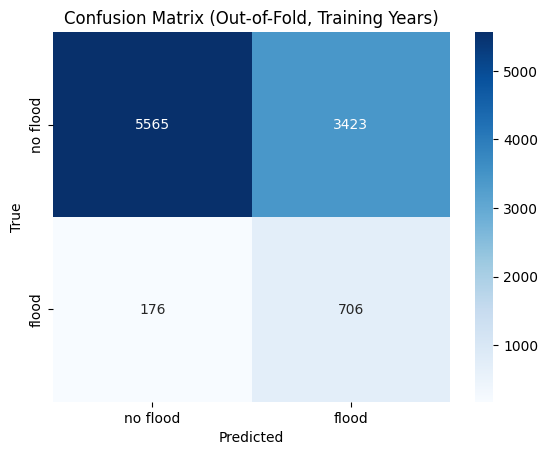

In [28]:
#heatmap of the out-of-fold confusion matrix
sns.heatmap(cm_oof, annot=True, fmt='d', cmap='Blues', xticklabels=['no flood', 'flood'], yticklabels=['no flood', 'flood'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (Out-of-Fold, Training Years)')
plt.show()

#### Observation

In the out-of-fold predictions of the training years (882 floods), the XGBoost model at the watch threshold of 0.343 finds 706 floods and misses 176. It gives 4,129 warnings, of which 3,423 are false alarms (a warning in a month with no flood). So there are far more false alarms than floods found, which agrees with the precision of 0.171 in Section 6.2. This is the price of a recall of 0.8: a lower threshold finds more floods and gives more false alarms, a higher one gives fewer false alarms and misses more floods (Section 6.5).

### 6.5 Other Recall Targets

The same steps for recall targets of 0.70 and 0.90, so the trade-off between recall and false alarms is visible.

In [29]:
#threshold, recall, precision and share of months flagged for three recall targets
targets = [0.70, 0.80, 0.90]
cut_list = []
recall_list = []
precision_list = []
flagged_list = []
for target in targets:
    cut = thresholds[recall[:-1] >= target].max()
    pred = (oof_prob >= cut).astype(int)
    cut_list.append(cut)
    recall_list.append(recall_score(y_train, pred))
    precision_list.append(precision_score(y_train, pred))
    flagged_list.append(pred.mean())
target_results = pd.DataFrame({'recall target': targets, 'threshold': cut_list, 'oof recall': recall_list,
                               'oof precision': precision_list, 'share of months flagged': flagged_list})
target_results.round(3)

,recall target,threshold,oof recall,oof precision,share of months flagged
0,0.7,0.437,0.701,0.235,0.266
1,0.8,0.343,0.800,0.171,0.418
2,0.9,0.265,0.900,0.143,0.562


### 6.6 The Threshold with the Highest F1 (for comparison)

F1 combines recall and precision. For comparison we also look for the threshold with the highest out-of-fold F1, next to the persistence baseline on the training rows (a flood this month means a flood next month).

In [30]:
#threshold with the highest out-of-fold f1
f1_values = pd.Series(2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1]))
best_f1_index = f1_values.idxmax()
print('threshold', round(thresholds[best_f1_index], 3))
print('recall', round(recall[best_f1_index], 3), 'precision', round(precision[best_f1_index], 3), 'f1', round(f1_values[best_f1_index], 3))
print('share of months flagged', round((oof_prob >= thresholds[best_f1_index]).mean(), 3))

threshold 0.713
recall 0.417 precision 0.571 f1 0.482
share of months flagged 0.065


In [31]:
#recall, precision and f1 of the persistence baseline on the training rows
print('recall', round(recall_score(y_train, train['flood_this_month']), 3))
print('precision', round(precision_score(y_train, train['flood_this_month']), 3))
print('f1', round(f1_score(y_train, train['flood_this_month']), 3))

recall 0.463
precision 0.463
f1 0.463


#### Observation

With a threshold of 0.343, the out-of-fold recall of the XGBoost model is 0.8 (the target was 0.80), the precision is 0.171 and the model flags 0.418 of all the training months. The table shows the trade-off: for a recall of 0.70 the threshold is 0.437, the precision is 0.235 and 0.266 of the months are flagged; for a recall of 0.90 the threshold is 0.265, the precision is 0.143 and 0.562 of the months are flagged. Every extra bit of recall costs more false alarms.

The threshold with the highest F1 is 0.713. It gives a recall of only 0.417, a precision of 0.571 and an F1 of 0.482, and flags only 0.065 of the months. The persistence baseline on the training rows has a recall of 0.463, a precision of 0.463 and an F1 of 0.463. So at its best F1 threshold the XGBoost model is about as good as the simple rule "a flood this month means a flood next month", and it does not catch more floods than that rule. This is why we set the threshold for 80% recall instead: recall is still the main goal, because a missed flood is the most dangerous mistake, and it is set by the threshold and not by weakening the model. The threshold comes from cross-validation only, and the test set was not used.

## 7. Evaluation on the Test Set

### 7.1 Predicting with the Chosen Threshold

The best settings of Section 4 were fitted on the whole training set (July 2002 to December 2019) by the search. The model is scored once on the test set (2020 to 2024), with the threshold of Section 6. A month gets a warning when its flood probability is at least the threshold. No setting is changed after this point.

In [32]:
#final model: the best settings, fitted on the full training set by the search
model = search.best_estimator_

In [33]:
#flood probabilities for the test set, and the warnings at the chosen threshold
y_prob = model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= threshold).astype(int)

### 7.2 Classification Report

In [34]:
#recall, precision and f1 for each class on the test set
print(classification_report(y_test, y_pred, target_names=['0 no flood', '1 flood']))

              precision    recall  f1-score   support

  0 no flood       1.00      0.61      0.76      2676
     1 flood       0.12      0.98      0.21       144

    accuracy                           0.63      2820
   macro avg       0.56      0.80      0.49      2820
weighted avg       0.95      0.63      0.73      2820



In [35]:
#recall, precision, f1, roc-auc and pr-auc of the test set
test_scores = pd.DataFrame({'recall': [recall_score(y_test, y_pred)],
                            'precision': [precision_score(y_test, y_pred)],
                            'f1': [f1_score(y_test, y_pred)],
                            'roc-auc': [roc_auc_score(y_test, y_prob)],
                            'pr-auc': [average_precision_score(y_test, y_prob)]})
test_scores.round(3)

,recall,precision,f1,roc-auc,pr-auc
0,0.979,0.12,0.214,0.904,0.374


#### Observation

On the test set, the XGBoost model with the threshold of 0.343 has a recall of 0.979, a precision of 0.12 and an F1 of 0.214. The ROC-AUC is 0.904 and the PR-AUC is 0.374; a model with no skill would score 0.051 in PR-AUC (the share of floods in the test set). The classification report agrees: the flood class has a recall of 0.98 and a precision of 0.12, and the no-flood class has a recall of 0.61. The model gives 1,172 warnings in the 2,820 test months, so most warnings are false alarms.

The test recall is higher than the 0.80 of cross-validation. The threshold was fixed in Section 6 before the test set was used, so this is a result and not a target we tuned. Notebook 05 looks at the test years one by one to see where the difference comes from.

### 7.3 Confusion Matrix

Each row is the true outcome and each column is the prediction, so the numbers on the diagonal are correct predictions.

In [36]:
#confusion matrix of the test set at the chosen threshold, and the number of warnings
cm = confusion_matrix(y_test, y_pred)
print(cm)
print('warnings', y_pred.sum())

[[1645 1031]
 [   3  141]]
warnings 1172


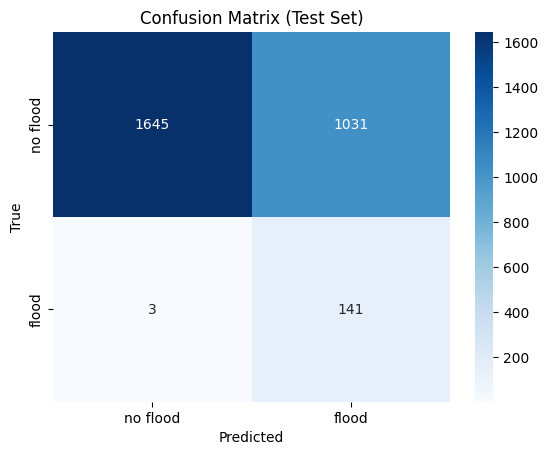

In [37]:
#heatmap of the test confusion matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['no flood', 'flood'], yticklabels=['no flood', 'flood'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (Test Set)')
plt.show()

#### Observation

On the test set (144 floods), the XGBoost model at the same threshold of 0.343 finds 141 floods and misses 3. It gives 1,172 warnings, of which 1,031 are false alarms. As in cross-validation there are far more false alarms than floods found (precision 0.12). The test recall (0.979) is higher than the out-of-fold recall (0.8), so a smaller share of the floods is missed. The threshold was not changed after the test set was used.

### 7.4 New Floods and Continuing Floods

A **new flood** is a flood next month in a county that did not flood this month (`flood_this_month` is 0). A **continuing flood** is a flood next month in a county that is already flooding this month (`flood_this_month` is 1). Continuing floods are easier to predict, so the two are scored separately.

In [38]:
#floods found among the new floods and among the continuing floods
new_floods = (y_test == 1) & (test['flood_this_month'] == 0)
continuing_floods = (y_test == 1) & (test['flood_this_month'] == 1)
print('new floods', new_floods.sum(), 'found', ((y_pred == 1) & new_floods).sum())
print('continuing floods', continuing_floods.sum(), 'found', ((y_pred == 1) & continuing_floods).sum())

new floods 76 found 73
continuing floods 68 found 68


In [39]:
#warnings in the months where the county is not flooding this month
print('warnings when the county is not flooding this month', ((y_pred == 1) & (test['flood_this_month'] == 0)).sum())
print('warnings when the county is flooding this month', ((y_pred == 1) & (test['flood_this_month'] == 1)).sum())

warnings when the county is not flooding this month 1028
warnings when the county is flooding this month 144


#### Observation

Among the new floods (the county was not flooding this month), the XGBoost model finds 73 of 76. Among the continuing floods (the county is already flooding this month), it finds 68 of 68. It gives 144 warnings in the months where the county is flooding this month (Section 8 shows that the persistence baseline warns 144 times, once for each of these months), so the continuing floods are found by this rule alone. The new floods are the real test, because the persistence baseline cannot find any of them. The model also gives 1028 warnings in months where the county is not flooding this month, and these are where almost all the false alarms come from.

### 7.5 Watch and Warning on the Test Set

Both thresholds were fixed in Section 6, before the test set was used. Here each level is scored on the test set (2020 to 2024). Nothing is changed after this point.

In [40]:
#test-set results for both levels: recall, precision, f1, alerts, floods found and new floods found
level_rows = []
for name, cut in [('Watch', watch_threshold), ('Warning', warning_threshold)]:
    pred = (y_prob >= cut).astype(int)
    level_rows.append({'level': name, 'threshold': cut, 'recall': recall_score(y_test, pred), 'precision': precision_score(y_test, pred),
                       'f1': f1_score(y_test, pred), 'alerts': pred.sum(), 'floods found': ((pred == 1) & (y_test == 1)).sum(),
                       'new floods found': ((pred == 1) & new_floods).sum()})
test_levels = pd.DataFrame(level_rows)
test_levels.round(3)

,level,threshold,recall,precision,f1,alerts,floods found,new floods found
0,Watch,0.343,0.979,0.120,0.214,1172,141,73
1,Warning,0.437,0.903,0.161,0.274,806,130,62


In [41]:
#every test warning is also above the watch line, and the number of false alarms at each level
print('warning alerts below the watch threshold', ((y_prob >= warning_threshold) & (y_prob < watch_threshold)).sum())
print('false alarms at watch', ((y_prob >= watch_threshold) & (y_test == 0)).sum())
print('false alarms at warning', ((y_prob >= warning_threshold) & (y_test == 0)).sum())

warning alerts below the watch threshold 0
false alarms at watch 1031
false alarms at warning 676


#### Observation

On the test set (144 floods in 2,820 months), the watch threshold finds 141 floods (recall 0.979, precision 0.120) with 1,172 alerts, 1,031 of them false alarms, and it finds 73 of the 76 new floods. The warning threshold finds 130 floods (recall 0.903, precision 0.161, F1 0.274) with 806 alerts, 676 of them false alarms, and it finds 62 of the 76 new floods. So Warning misses 11 more floods than Watch (141 to 130, all of them new floods: 73 to 62), but it gives 366 fewer alerts and 355 fewer false alarms. As before, the test recall is higher than the cross-validation recall (0.979 against 0.80 for Watch, 0.903 against 0.70 for Warning), so the cross-validation numbers are the more careful ones to plan with. Even at the Warning level only about 1 alert in 6 is a real flood (precision 0.161), so most alerts are still false alarms. Every test Warning is also above the Watch line (0 rows in between).

## 8. Comparison with Two Baselines

A model is only useful if it does better than simple rules that need no model. We compare it with two:

- **Persistence baseline:** predicts a flood next month whenever there is a flood this month (`flood_this_month`). It tests whether the model knows more than the current situation.
- **Calendar baseline:** gives every row the flood rate of its calendar month in the training years, so every March row gets the March rate, whatever the county or the rain. It tests whether the model knows more than the time of year. For a yes/no prediction it flags the months whose flood rate is above the overall training rate.

In [42]:
#persistence baseline predictions on the test set
base_pred = test['flood_this_month']

In [43]:
#flood rate of each calendar month in the training years
month_rate = train.groupby('month')['flood_next_month'].mean()
month_rate.round(3)

month
1     0.016
2     0.090
3     0.183
4     0.185
5     0.054
6     0.020
7     0.046
8     0.044
9     0.069
10    0.131
11    0.134
12    0.102
Name: flood_next_month, dtype: float64

In [44]:
#calendar baseline on the test set: the rate of the month, and yes/no when the rate is above the overall rate
calendar_prob = test['month'].map(month_rate)
calendar_pred = (calendar_prob > y_train.mean()).astype(int)

In [45]:
#months flagged by the calendar baseline and the number of test rows it flags
print(month_rate[month_rate > y_train.mean()].index.tolist())
print(calendar_pred.sum())

[2, 3, 4, 10, 11, 12]
1410


### 8.1 The Three Methods Side by Side

PR-AUC (average precision) does not depend on a probability cut, but it focuses on the flood class: a method with no skill scores the flood share of the test set (0.051). The number of different probabilities the model gives is checked first: rows with the same probability are tied in the rankings behind ROC-AUC and PR-AUC.

In [46]:
#number of different flood probabilities the model gives on the test set
pd.Series(y_prob).nunique()

2576

In [47]:
#recall, precision, f1, roc-auc, pr-auc and warnings for the two baselines and the model
comparison = pd.DataFrame({'method': ['Persistence baseline', 'Calendar baseline', 'XGBoost'],
                           'recall': [recall_score(y_test, base_pred), recall_score(y_test, calendar_pred), recall_score(y_test, y_pred)],
                           'precision': [precision_score(y_test, base_pred), precision_score(y_test, calendar_pred), precision_score(y_test, y_pred)],
                           'f1': [f1_score(y_test, base_pred), f1_score(y_test, calendar_pred), f1_score(y_test, y_pred)],
                           'roc-auc': [roc_auc_score(y_test, base_pred), roc_auc_score(y_test, calendar_prob), roc_auc_score(y_test, y_prob)],
                           'pr-auc': [average_precision_score(y_test, base_pred), average_precision_score(y_test, calendar_prob), average_precision_score(y_test, y_prob)],
                           'warnings': [base_pred.sum(), calendar_pred.sum(), y_pred.sum()]})
comparison.round(3)

,method,recall,precision,f1,roc-auc,pr-auc,warnings
0,Persistence baseline,0.472,0.472,0.472,0.722,0.250,144
1,Calendar baseline,0.847,0.087,0.157,0.762,0.141,1410
2,XGBoost,0.979,0.120,0.214,0.904,0.374,1172


#### Observation

The persistence baseline has a recall of 0.472 and also a precision of 0.472 with 144 warnings. The calendar baseline has a recall of 0.847 but a precision of 0.087 with 1410 warnings. The XGBoost model has a recall of 0.979 and a precision of 0.12 with 1,172 warnings. It is better than both baselines in ROC-AUC (0.904 against 0.722 and 0.762) and in PR-AUC (0.374 against 0.250 and 0.141), and its recall is higher than both. But persistence has a higher precision (0.472) and a higher F1 (0.472 against 0.214), because it gives far fewer warnings. So the model buys its higher recall with many more warnings, and persistence alone is a strong rule. The ROC-AUC and PR-AUC of the two baselines are calculated from yes/no predictions and not from probabilities, so they are only a rough guide. XGBoost gives 2576 different probabilities in the test set, so only a few rows are tied.

### 8.2 A Fair Recall Comparison

Recall depends on how many warnings a method raises: a method that flags more months will usually find more floods. To compare the model and the calendar baseline fairly, we let the model raise as many warnings as the calendar baseline, on the rows it thinks are most likely to flood. This is only a comparison, not a way of choosing the threshold. Rows with exactly the same probability cannot be told apart, so the number of floods found is given as a range.

In [48]:
#number of warnings raised by the calendar baseline and by the model
print(calendar_pred.sum())
print(y_pred.sum())

1410
1172


In [49]:
#ranking the test rows from the highest to the lowest flood probability
test_ranked = test.copy()
test_ranked['prob'] = y_prob
test_ranked = test_ranked.sort_values('prob', ascending=False)

In [50]:
#probability of the last warning if the model raised as many warnings as the calendar baseline
cut_prob = test_ranked['prob'].iloc[calendar_pred.sum() - 1]
print(cut_prob)

0.28686744


In [51]:
#warnings and floods found with a probability above the cut, and with a probability above or equal to the cut
above = test_ranked[test_ranked['prob'] > cut_prob]
print(len(above), above['flood_next_month'].sum())
equal_or_above = test_ranked[test_ranked['prob'] >= cut_prob]
print(len(equal_or_above), equal_or_above['flood_next_month'].sum())

1409 142
1410 142


#### Observation

The calendar baseline gives 1410 warnings and the XGBoost model gives 1,172. If the XGBoost model gave as many warnings as the calendar baseline, with the cut at the probability 0.287, it would give 1409 warnings and 142 floods (probability above the cut) or 1410 warnings and 142 floods (above or equal to the cut), so one tied row does not change the number of floods found. It would find 142 of the 144 floods. The calendar baseline has a recall of 0.847 with its 1410 warnings (table in Section 8.1), so with the same number of warnings the XGBoost model finds more floods than the calendar rule.

## 9. Looking Inside the Model

XGBoost adds up the answers of many small trees, so it cannot be read like a single flowchart. Here we look at which features the model used most.

### 9.1 Feature Importance

The importance of a feature is how much it improved the fit of the model in the questions that used it (the gain), scaled so that all 25 values add up to 1. Features the model never used have an importance of 0, and when two features carry similar information, the importance may be shared between them. The column `splits` counts how many questions in all the trees were asked about the feature.

In [52]:
#importance of each feature and number of questions that used it, from the highest to the lowest
importance = pd.DataFrame({'feature': X_train.columns, 'importance': model.feature_importances_})
splits = model.get_booster().get_score(importance_type='weight')
importance['splits'] = importance['feature'].map(splits).fillna(0).astype(int)
importance = importance.sort_values('importance', ascending=False)
importance.round(3)

,feature,importance,splits
0,flood_this_month,0.379,227
24,county_flood_rate,0.084,268
7,oni,0.057,433
9,month_sin,0.053,257
8,dmi,0.048,439
11,soil_moisture_l1,0.043,39
10,month_cos,0.041,241
5,neighbour_rain,0.032,322
6,ndvi_pct_normal,0.030,39
18,lc_crop,0.030,4


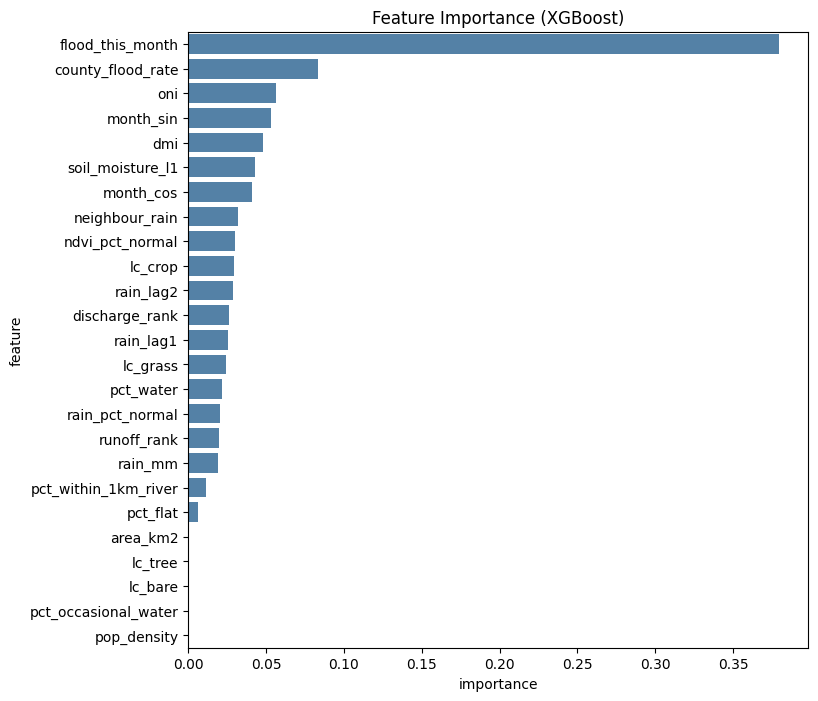

In [53]:
#bar chart of the feature importance
plt.figure(figsize=(8, 8))
sns.barplot(data=importance, x='importance', y='feature', color='steelblue')
plt.title('Feature Importance (XGBoost)')
plt.show()

#### Observation

`flood_this_month` is the most important feature (0.379). Then come `county_flood_rate` (0.084), `oni` (0.057), `month_sin` (0.053), `dmi` (0.048) and `soil_moisture_l1` (0.043). `oni` and `dmi` are used in the most questions (433 and 439 splits), and `county_flood_rate` in 268. Five features have an importance of 0.000 and 0 splits: `area_km2`, `lc_tree`, `lc_bare`, `pct_occasional_water` and `pop_density`, so the model does not use them at all. The other 20 features are used at least once.

## 10. Saving the Model

The final model is saved with `joblib` and its settings and both thresholds are saved in a `json` file, so that `05_model_comparison.ipynb` can load them instead of copying the settings by hand.

In [54]:
#creating the models folder if it does not exist yet
os.makedirs('../models', exist_ok=True)

In [55]:
#saving the final model
joblib.dump(model, '../models/xgboost.joblib', compress=3)

['../models/xgboost.joblib']

In [56]:
#best settings as plain python values so they can be saved in a json file
best_params = {}
for name, value in search.best_params_.items():
    if hasattr(value, 'item'):
        value = value.item()
    best_params[name] = value

In [57]:
#saving the settings, both thresholds (threshold is the same as watch_threshold, so notebook 05 still works) and the cross-validation scores
settings = {'model': 'XGBoost',
            'best_params': best_params,
            'threshold': float(threshold),
            'recall_target': 0.80,
            'cv_pr_auc_mean': float(search.best_score_),
            'cv_pr_auc_std': float(results.loc[search.best_index_, 'std_test_score']),
            'oof_recall': float(recall_score(y_train, oof_pred)),
            'oof_precision': float(precision_score(y_train, oof_pred)),
            'share_flagged': float(oof_pred.mean()),
            'watch_threshold': float(watch_threshold),
            'warning_threshold': float(warning_threshold),
            'warning_recall_target': 0.70,
            'warning_oof_recall': float(recall_score(y_train, (oof_prob >= warning_threshold).astype(int))),
            'warning_oof_precision': float(precision_score(y_train, (oof_prob >= warning_threshold).astype(int))),
            'warning_share_flagged': float((oof_prob >= warning_threshold).mean())}
with open('../models/xgboost_settings.json', 'w') as settings_file:
    json.dump(settings, settings_file, indent=2)
print(settings)

{'model': 'XGBoost', 'best_params': {'subsample': 1.0, 'scale_pos_weight': 10.19047619047619, 'reg_lambda': 5, 'n_estimators': 400, 'min_child_weight': 50, 'max_depth': 3, 'learning_rate': 0.01, 'colsample_bytree': 1.0}, 'threshold': 0.34251049160957336, 'recall_target': 0.8, 'cv_pr_auc_mean': 0.47638480790761867, 'cv_pr_auc_std': 0.0800824120866552, 'oof_recall': 0.800453514739229, 'oof_precision': 0.17098571082586583, 'share_flagged': 0.41833839918946303, 'watch_threshold': 0.34251049160957336, 'warning_threshold': 0.4373789131641388, 'warning_recall_target': 0.7, 'warning_oof_recall': 0.7006802721088435, 'warning_oof_precision': 0.2349809885931559, 'warning_share_flagged': 0.26646403242147926}


In [58]:
#files in the models folder
print(os.listdir('../models'))

['decision_tree.joblib', 'decision_tree_settings.json', 'logistic_regression.joblib', 'logistic_regression_settings.json', 'random_forest.joblib', 'random_forest_settings.json', 'xgboost.joblib', 'xgboost_settings.json']


## 11. Summary of the XGBoost Model

- **Method:** Final settings: `XGBClassifier` with `max_depth` = 3, `n_estimators` = 400, `learning_rate` = 0.01, `subsample` = 1.0, `colsample_bytree` = 1.0, `min_child_weight` = 50, `reg_lambda` = 5 and `scale_pos_weight` = 10.19. The settings were chosen with `RandomizedSearchCV` scored with PR-AUC on 5 folds that keep whole years together (Job 1). The thresholds were then chosen for 80% out-of-fold recall (Watch) and 70% out-of-fold recall (Warning) (Job 2), using cross-validation only.
- **Cross-validation:** mean PR-AUC 0.476 (std 0.080 between the folds).
- **Watch threshold:** 0.343 (80% out-of-fold recall). The out-of-fold recall is 0.8, the precision is 0.171 and 0.418 of the months are flagged. It means "be ready".
- **Warning threshold:** 0.437 (70% out-of-fold recall). The out-of-fold recall is 0.701, the precision is 0.235 and 0.266 of the months are flagged. It means "act now". Every Warning is also above the Watch line.
- **Test set (used once), Watch:** recall 0.979, precision 0.12, F1 0.214, ROC-AUC 0.904, PR-AUC 0.374, with 1,172 warnings in 2,820 months. New floods found: 73 of 76. Continuing floods found: 68 of 68.
- **Test set (used once), Warning:** recall 0.903, precision 0.161, F1 0.274, with 806 warnings in 2,820 months. New floods found: 62 of 76.
- **Baselines:** the model has a higher recall, ROC-AUC and PR-AUC than the persistence and calendar baselines, but the persistence baseline has a higher precision and F1 because it warns only 144 times.
- **Overfitting gap (PR-AUC):** the default XGBoost has 1.000 on the training rows and 0.386 in cross-validation; the best model has 0.622 and 0.476.
- **Edge of the lists:** after the lists were extended once, `learning_rate` = 0.01 (smallest) and `min_child_weight` = 50 (largest) are still at the edge of their lists.
- **Saved:** the fitted model and its settings and both thresholds are saved in the `models` folder for `05_model_comparison.ipynb`.
- **Limits that stay:** (1) the folds hold out whole years but train on years before and after them, so cross-validation is not a pure forecast of the future; (2) `county_flood_rate` is calculated from all the training years, so the cross-validation scores are slightly optimistic; (3) the data stops in December 2024 (no 2025 data was added).
- **Feature selection:** the 24 features were chosen in the EDA notebooks using only the training rows (July 2002 to December 2019), so the test years were not used to choose them.

The next notebook, `05_model_comparison.ipynb`, compares all four models.